# Robustez · Fase 1

Comprueba si los resultados de la fase 1 (`05_fase1_v2`, la versión definitiva) **se mantienen** cuando se cambia una decisión del análisis por otra razonable. Si la conclusión no cambia, el resultado es **robusto**; si cambia, hay que reportarlo y explicar por qué.

**Qué pruebas se hacen y de dónde salen.** No se inventa ninguna prueba: son las de la lista de robustez de la propia metodología (`metodologia.md` §4 y decisión D‑29), que aplican a la fase 1. Cada una cambia **una sola cosa** respecto del modelo principal:

| Código | Prueba | Qué se cambia | Por qué (decisión) | Tipo |
|---|---|---|---|---|
| `principal` | Modelo principal | Nada: reproduce `05_fase1_v2` | — | Referencia |
| `efectos_fijos_semana` | Efectos fijos de semana | El efecto fijo de **mes** se reemplaza por uno de **semana** | D‑16: opción (b2), más protegida contra campañas estacionales | Especificación |
| `sin_diciembre` | Sin diciembre | Se excluye diciembre de 2016 | `metodologia.md` §4.1: la Navidad se confunde con campañas | Corte de tiempo |
| `terremoto_corto` | Ventana corta del terremoto | Se excluye solo hasta el 16‑05‑2016 (en vez del 31‑05) y se recalculan los rezagos | D‑09: robustez acordada | Corte de tiempo |
| `skus_todo_el_periodo` | SKUs presentes todo el período | Solo los SKUs que existen los 590 días | D‑24: universo alternativo | Submuestra |
| `placebo_adelanto` | Placebo con adelantos | Se agrega la promoción **de los 3 días siguientes** del propio SKU | `metodologia.md` fase 1: "adelantos como placebo" | Falsificación |
| — | Corrección al 10 % | Benjamini‑Hochberg al 10 % en vez de 5 % (sin reestimar) | D‑15: "5 % salvo que se acuerde 10 %" | Parámetro |

**Qué no se hace y por qué** (se declara como limitación):

- **Cotas de la imputación de promociones (D‑25):** exigiría rehacer `03_exposiciones` con otra regla de imputación.
- **Otra tienda:** exigiría volver a extraer los datos desde `train.csv`.
- **$\log(1+N)$ y "sin resto":** son pruebas de la fase 2 (cambian la intensidad de otras categorías), no de la fase 1.

| | |
|---|---|
| **Entrada** | `panel_t44_sku_dia.parquet`, `exposiciones_t44_sku_dia.parquet`, `calendario_t44.csv` (los mismos de `05_fase1_v2`); `fase1v2_coeficientes.csv` solo para verificar, si existe |
| **Tablas** (en `resultados/tablas/`) | `robustez_fase1_coeficientes.csv`, `robustez_fase1_efecto_neto.csv`, `robustez_fase1_consistencia.csv`, `robustez_fase1_resumen.csv`, `robustez_fase1_placebo.csv`, `robustez_fase1_bh10.csv`, `robustez_fase1_muestras.csv` |
| **Figura** (en `resultados/figuras/`) | `robustez_fase1_efectos.png` |
| **No modifica** | ningún notebook ni archivo existente: todas las salidas empiezan con `robustez_fase1_` |

**Nota sobre la metodología.** La decisión D‑29 dejó la robustez fuera de alcance por el plazo del póster. El equipo decidió hacerla antes de la presentación; conviene informarlo al profesor guía y actualizar la limitación "Sin análisis de robustez" de `metodologia.tex`.

## Guía rápida: qué es una prueba de robustez y cómo se lee

**La idea.** Todo análisis toma decisiones que podrían haber sido otras igual de razonables: usar el mes o la semana para controlar la estacionalidad, excluir 46 o 31 días del terremoto, etc. Una prueba de robustez **repite el mismo análisis cambiando una de esas decisiones** y mira si la conclusión sigue en pie. Es como pesar algo en dos balanzas distintas: si las dos dan casi lo mismo, uno confía en el peso.

**Qué se compara** (en cada prueba, para cada categoría y cada tipo de promoción):

| Pregunta | Columna | Lectura |
|---|---|---|
| ¿El efecto apunta en la misma dirección? | `mismo_signo` | Debe ser `True` casi siempre. |
| ¿La conclusión es la misma? | `misma_conclusion` | Positivo significativo / negativo significativo / no significativo: debe coincidir. |
| ¿Cuánto cambia el tamaño? | `diferencia_pp` | Diferencia en puntos porcentuales entre la prueba y el principal. |
| ¿El nuevo valor cae dentro del intervalo del principal? | `dentro_ic_principal` | Si es `True`, la diferencia es compatible con el azar del muestreo. |

**El placebo es distinto.** No busca que el resultado se mantenga, sino **que no aparezca nada**: la promoción de los próximos días no puede causar las ventas de hoy. Si su efecto sale significativo, puede ser que (a) la cadena promociona justo cuando espera que la demanda cambie, o (b) los clientes **esperan** la promoción y compran menos antes (un efecto real que conviene comentar). Ninguna de las dos invalida el análisis, pero hay que discutirlas.

**Cómo se interpreta un cambio.** Que un resultado cambie en una prueba **no significa que esté mal**: indica que depende de esa decisión, y eso se reporta. Es especialmente esperable en categorías con poca información (MEATS y POULTRY tienen solo unos cientos de SKU‑días en promoción fuera del programa).

## Paso 1. Librerías y parámetros

Los parámetros del modelo son **copias exactas** de `05_fase1_v2`. Los nuevos son los de las pruebas de robustez.

In [1]:
# ------------------------------------------------------------------------------------------------------------
# Este notebook aplica las pruebas de robustez de la metodología (metodologia.md §4, D-29) a la fase 1
# (05_fase1_v2): efectos fijos de semana, sin diciembre, ventana corta del terremoto, SKUs presentes todo el
# período, placebo con adelantos y corrección de Benjamini-Hochberg al 10 %.
# ------------------------------------------------------------------------------------------------------------
# Implementación: NachaJavi (con asistencia de Claude), a partir de 05_fase1_v2
# Fecha de versión: 2026-11-11
# ------------------------------------------------------------------------------------------------------------

# Librerías
# ------------------------------------------------------------------------------------------------------------
import os
import warnings

import numpy as np
import pandas as pd
import pyfixest as pf
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests

# pyfixest avisa cuando un control de calendario de uno o dos días queda sin error estándar, y cuando elimina
# SKUs con una sola observación; no afecta a las variables de promoción
warnings.filterwarnings("ignore", message="invalid value encountered in sqrt")
warnings.filterwarnings("ignore", message=".*singleton.*")

# Parámetros del modelo (copiados de 05_fase1_v2)
# ------------------------------------------------------------------------------------------------------------
categorias = [
    "BEVERAGES", "GROCERY I", "CLEANING", "DAIRY", "BREAD/BAKERY", "LIQUOR,WINE,BEER",
    "MEATS", "POULTRY", "DELI", "PRODUCE",
]

# D-14: promoción propia, de la clase y del resto de la categoría, cada una con sus bloques de rezagos
regresores_promocion = [
    "onpromotion", "onpromotion_l1_3", "onpromotion_l4_6",
    "promo_clase_otros", "promo_clase_otros_l1_3", "promo_clase_otros_l4_6",
    "promo_cat_otras_clases", "promo_cat_otras_clases_l1_3", "promo_cat_otras_clases_l4_6",
]

# D-10 y D-13: controles de calendario
controles_calendario = [
    "dia_libre", "adicional", "dia_laboral_recuperado", "evento_comercial", "evento_otro", "dia_pago", "post_pago",
]

variable_dependiente = "unit_sales_ppml"   # D-08, D-20
efectos_fijos = "item_nbr + dow + mes"     # D-16
agrupamiento = "item_nbr + semana"         # D-15

# D-14: bloques de rezagos (días de operación anteriores), los mismos de 03_exposiciones
bloques = {"l1_3": [1, 2, 3], "l4_6": [4, 5, 6]}
columnas_rezagos = [c for c in regresores_promocion if c.endswith(tuple(bloques))]

# Ventanas que se excluyen de la estimación de una categoría (igual que 05_fase1_v2)
ventanas_excluidas = {"MEATS": [("2017-06-03", "2017-06-21")]}

# Parámetros de las pruebas de robustez
# ------------------------------------------------------------------------------------------------------------
# Las pruebas que se reestiman, en el orden en que se muestran; cada una cambia una sola cosa del principal
especificaciones = {
    "principal":            "Modelo principal (05_fase1_v2)",
    "efectos_fijos_semana": "Efectos fijos de semana en vez de mes (D-16)",
    "sin_diciembre":        "Sin diciembre de 2016",
    "terremoto_corto":      "Ventana del terremoto hasta el 16-05-2016 (D-09)",
    "skus_todo_el_periodo": "Solo SKUs presentes los 590 días (D-24)",
    "placebo_adelanto":     "Placebo: promoción propia de los 3 días siguientes",
}
efectos_fijos_semana = "item_nbr + dow + semana"   # D-16, opción (b2)
mes_excluido = 12                                  # diciembre
bloque_adelanto = {"f1_3": [-1, -2, -3]}           # los mismos adelantos de 03_exposiciones
alfa = 0.05                                        # D-15
alfa_alternativo = 0.10                            # D-15: "5 % salvo que se acuerde 10 %"

# Variables cuya estabilidad se compara (el día de la promoción, como en las figuras de la fase 1)
variables_comparadas = {
    "onpromotion":            "Propio (día)",
    "promo_clase_otros":      "Misma clase (día, +10 pp)",
    "promo_cat_otras_clases": "Resto de la categoría (día, +10 pp)",
}

# Rutas
# ------------------------------------------------------------------------------------------------------------
ruta_procesados = os.path.join("..", "data", "procesados")
ruta_tablas = os.path.join("resultados", "tablas")
ruta_figuras = os.path.join("resultados", "figuras")
os.makedirs(ruta_tablas, exist_ok=True)
os.makedirs(ruta_figuras, exist_ok=True)
prefijo = "robustez_fase1"
archivo_principal_05 = os.path.join(ruta_tablas, "fase1v2_coeficientes.csv")   # solo para verificar

## Paso 2. Importar los datos

Los mismos tres archivos de `05_fase1_v2`, con el mismo índice de día de operación `t`. Además se definen las fechas que usan las pruebas:

- **Ventana corta del terremoto:** los días con la marca `terremoto` del calendario (los eventos del terremoto en `holidays_events.csv`, del 16‑04 al 16‑05‑2016). Así la fecha de corte sale de los datos, no se escribe a mano.
- **SKUs presentes todo el período:** los que tienen una fila en el panel en cada uno de los 590 días de operación.

In [2]:
panel = pd.read_parquet(os.path.join(ruta_procesados, "panel_t44_sku_dia.parquet"))
exposiciones = pd.read_parquet(os.path.join(ruta_procesados, "exposiciones_t44_sku_dia.parquet"))
calendario = pd.read_csv(os.path.join(ruta_procesados, "calendario_t44.csv"), parse_dates=["date"])

# Numerar los días con operación (t = 0, ..., 589), igual que en 03_exposiciones y 05_fase1_v2
calendario = calendario.sort_values("date").reset_index(drop=True)
calendario["t"] = np.arange(len(calendario))

# Identificar las categorías con programa semanal fijo (igual que 05_fase1_v2)
skus_programa = exposiciones.loc[exposiciones["dia_programa"], "item_nbr"].unique()
familias_programa = set(panel.loc[panel["item_nbr"].isin(skus_programa), "family"].astype(str))
categorias_programa = [c for c in categorias if c in familias_programa]

# Ventana corta del terremoto: los días marcados como evento del terremoto en el calendario (D-09)
calendario["ventana_terremoto_corta"] = calendario["terremoto"].astype(bool)
assert calendario.loc[calendario["ventana_terremoto_corta"], "ventana_terremoto"].all(), \
    "la ventana corta debe estar dentro de la ventana larga"

# SKUs presentes todo el período: una fila en cada día de operación (D-24)
dias_por_sku = panel.groupby("item_nbr").size()
skus_todo_el_periodo = set(dias_por_sku.index[dias_por_sku == len(calendario)])

print(f"panel:        {len(panel):,} SKU-días")
print(f"exposiciones: {len(exposiciones):,} SKU-días")
print(f"calendario:   {len(calendario):,} días")
print(f"categorías con programa entre las modeladas: {categorias_programa}")
v_larga, v_corta = calendario["ventana_terremoto"], calendario["ventana_terremoto_corta"]
print(f"ventana del terremoto: larga = {v_larga.sum()} días (hasta {calendario.loc[v_larga, 'date'].max():%d-%m-%Y}), "
      f"corta = {v_corta.sum()} días (hasta {calendario.loc[v_corta, 'date'].max():%d-%m-%Y})")
print(f"días de diciembre que se excluyen: {(calendario['date'].dt.month == mes_excluido).sum()}")
print(f"SKUs presentes los {len(calendario)} días: {len(skus_todo_el_periodo):,} de {panel['item_nbr'].nunique():,}")

panel:        1,935,758 SKU-días
exposiciones: 1,935,758 SKU-días
calendario:   590 días
categorías con programa entre las modeladas: ['MEATS', 'POULTRY', 'DELI', 'PRODUCE']
ventana del terremoto: larga = 46 días (hasta 31-05-2016), corta = 31 días (hasta 16-05-2016)
días de diciembre que se excluyen: 30
SKUs presentes los 590 días: 2,122 de 3,656


**Cómo leer esta salida.** Las tres primeras líneas deben coincidir con `05_fase1_v2` (1.935.758 SKU‑días, 590 días). Luego se ve cuántos días saca cada corte y cuántos SKUs quedan en la submuestra.

## Paso 3. Funciones de rezagos y adelantos

`promedio_bloques` y `rezagos_fuera_programa` son **copias exactas** de `05_fase1_v2`. Se usan para dos cosas:

1. Igual que en `05_fase1_v2`: en las categorías con programa, los rezagos se calculan sin el día de programa.
2. **Nuevo (prueba `terremoto_corto`):** con la ventana corta, los días del 17 al 31 de mayo vuelven a la muestra, y los rezagos que `03_exposiciones` dejó vacíos por tocar la ventana larga se recalculan.

`adelantos_fuera_programa` es nueva: calcula la promoción propia de los **3 días siguientes** (placebo), con las mismas reglas que `03_exposiciones` usa para sus adelantos (`_f1_3`).

**Verificación.** Antes de usarlas se comprueba que reproducen exactamente las columnas de `03_exposiciones` (rezagos y adelantos), igual que hace `05_fase1_v2`.

In [3]:
def promedio_bloques(datos: pd.DataFrame, columna: str, relleno_fuera_ventana: float) -> dict:
    """
    Esta función calcula el promedio de una variable SKU-día en cada bloque de días de operación anteriores, con
    las mismas reglas que 03_exposiciones. (Copia exacta de 05_fase1_v2.)

    :param datos:                   un DataFrame de una categoría ordenado por SKU y fecha, con las columnas
                                    item_nbr, t (índice del día de operación) y ventana_terremoto.
    :param columna:                 el nombre de la variable a desplazar.
    :param relleno_fuera_ventana:   el valor para los días fuera de la ventana de vida del SKU (0.0 o np.nan).
    :return:                        un diccionario {sufijo del bloque: serie con el promedio del bloque}.
    """

    # Anular los días de la ventana del terremoto para que no entren a ningún bloque
    valores = datos[columna].astype(float).where(~datos["ventana_terremoto"])
    por_sku = valores.groupby(datos["item_nbr"])

    # Posición de cada fila dentro de la ventana de vida del SKU
    pos_inicio = datos.groupby("item_nbr").cumcount()

    resultado = {}
    for sufijo, desplazamientos in bloques.items():
        desplazadas = []
        for k in desplazamientos:
            # Desplazar k días de operación; rellenar fuera de la ventana de vida y anular fuera del período
            s = por_sku.shift(k).where(pos_inicio >= k, relleno_fuera_ventana).where(datos["t"] - k >= 0)
            desplazadas.append(s)

        # Promediar el bloque; si falta algún día, el bloque queda nulo
        resultado[sufijo] = pd.concat(desplazadas, axis=1).mean(axis=1, skipna=False).astype("float32")

    return resultado


def rezagos_fuera_programa(datos: pd.DataFrame, contar_programa: bool = False) -> pd.DataFrame:
    """
    Esta función recalcula los bloques de rezagos de la promoción propia, de la clase y del resto de la categoría
    para una categoría. Con contar_programa=False, la promoción del día de programa cuenta como cero.
    (Copia exacta de 05_fase1_v2.)

    :param datos:               un DataFrame con todos los SKU-días de una categoría (incluidos los días de
                                programa y de la ventana del terremoto), con las columnas item_nbr, date, class,
                                onpromotion, dia_programa, t y ventana_terremoto.
    :param contar_programa:     si es True, el día de programa cuenta como promoción y se reproducen los rezagos
                                de 03_exposiciones (sirve para verificar). Default is False.
    :return:                    un DataFrame con item_nbr, date y las seis columnas de rezagos.
    """

    # Ordenar por SKU y fecha, y verificar que los días de operación sean consecutivos dentro de cada SKU
    d = datos.sort_values(["item_nbr", "date"]).reset_index(drop=True)
    assert (d.groupby("item_nbr")["t"].diff().dropna() == 1).all(), "faltan días dentro de la ventana de algún SKU"

    # Definir la promoción que entra a los rezagos: fuera del programa (o toda, para verificar)
    if contar_programa:
        d["promo"] = d["onpromotion"].astype(int)
    else:
        d["promo"] = (d["onpromotion"] & ~d["dia_programa"]).astype(int)

    # Contar SKUs activos y en promoción por clase y por categoría en cada día
    por_clase = d.groupby(["class", "date"], observed=True)["promo"]
    n_activos_clase = por_clase.transform("size")
    n_promo_clase = por_clase.transform("sum")
    por_categoria = d.groupby("date", observed=True)["promo"]
    n_activos_cat = por_categoria.transform("size")
    n_promo_cat = por_categoria.transform("sum")

    # Calcular la proporción en promoción de los otros SKUs de la clase y de las otras clases de la categoría
    otros_clase = n_activos_clase - 1
    d["clase"] = ((n_promo_clase - d["promo"]) / otros_clase).where(otros_clase > 0)
    otras_clases = n_activos_cat - n_activos_clase
    d["cat"] = ((n_promo_cat - n_promo_clase) / otras_clases).where(otras_clases > 0)

    # Promediar cada variable en los bloques de rezagos
    salida = d[["item_nbr", "date"]].copy()
    variables = [
        ("promo", "onpromotion", 0.0),
        ("clase", "promo_clase_otros", np.nan),
        ("cat", "promo_cat_otras_clases", np.nan),
    ]
    for columna, nombre, relleno in variables:
        for sufijo, serie in promedio_bloques(d, columna, relleno).items():
            salida[f"{nombre}_{sufijo}"] = serie

    return salida


def adelantos_fuera_programa(datos: pd.DataFrame, contar_programa: bool = False) -> pd.DataFrame:
    """
    Esta función calcula el promedio de la promoción propia en los 3 días de operación siguientes (placebo), con las
    reglas que 03_exposiciones usa para sus adelantos: la ventana del terremoto queda nula, fuera de la ventana de
    vida del SKU la promoción vale 0 y después del último día del período el bloque queda nulo.

    :param datos:               un DataFrame con todos los SKU-días de una categoría, con las columnas item_nbr,
                                date, onpromotion, dia_programa, t y ventana_terremoto.
    :param contar_programa:     si es True, el día de programa cuenta como promoción (reproduce 03_exposiciones);
                                si es False, cuenta como cero (igual criterio que los rezagos de 05_fase1_v2).
    :return:                    un DataFrame con item_nbr, date y la columna onpromotion_f1_3.
    """

    # Ordenar por SKU y fecha, y definir la promoción que entra al adelanto
    d = datos.sort_values(["item_nbr", "date"]).reset_index(drop=True)
    promo = d["onpromotion"] if contar_programa else d["onpromotion"] & ~d["dia_programa"]
    valores = promo.astype(float).where(~d["ventana_terremoto"])
    por_sku = valores.groupby(d["item_nbr"])

    # Posición de cada fila contada desde el final de la ventana de vida del SKU
    pos_final = d.groupby("item_nbr").cumcount(ascending=False)
    ultimo_t = calendario["t"].max()

    salida = d[["item_nbr", "date"]].copy()
    for sufijo, desplazamientos in bloque_adelanto.items():
        desplazadas = []
        for k in desplazamientos:
            # Desplazar -k días hacia adelante; 0 fuera de la ventana de vida, nulo después del período
            s = por_sku.shift(k).where(pos_final >= -k, 0.0).where(d["t"] - k <= ultimo_t)
            desplazadas.append(s)
        salida[f"onpromotion_{sufijo}"] = pd.concat(desplazadas, axis=1).mean(axis=1, skipna=False).astype("float32")

    return salida

In [4]:
# Verificar que, contando el día de programa, las funciones reproducen las columnas de 03_exposiciones.
# Se revisa una categoría con programa y una sin programa (las más pequeñas de cada grupo, para que sea rápido).
for categoria in ["POULTRY", "LIQUOR,WINE,BEER"]:
    datos_cat = (
        panel.loc[panel["family"] == categoria]
        .merge(exposiciones, on=["item_nbr", "date"], how="left")
        .merge(calendario, on="date", how="left")
    )
    reconstruidos = (
        rezagos_fuera_programa(datos_cat, contar_programa=True)
        .merge(adelantos_fuera_programa(datos_cat, contar_programa=True), on=["item_nbr", "date"])
        .merge(datos_cat[["item_nbr", "date"] + columnas_rezagos + ["onpromotion_f1_3"]], on=["item_nbr", "date"],
               suffixes=("_nuevo", ""))
    )
    for columna in columnas_rezagos + ["onpromotion_f1_3"]:
        nuevo, original = reconstruidos[f"{columna}_nuevo"], reconstruidos[columna]
        assert (nuevo.isna() == original.isna()).all(), f"{categoria}, {columna}: los nulos no coinciden"
        assert (nuevo - original).abs().max() < 1e-5, f"{categoria}, {columna}: los valores no coinciden"
    print(f"{categoria:17s} la reconstrucción coincide con 03_exposiciones en {len(columnas_rezagos) + 1} columnas "
          f"(6 rezagos y el adelanto)")

POULTRY           la reconstrucción coincide con 03_exposiciones en 7 columnas (6 rezagos y el adelanto)
LIQUOR,WINE,BEER  la reconstrucción coincide con 03_exposiciones en 7 columnas (6 rezagos y el adelanto)


**Cómo leer esta salida.** Dos líneas que dicen "la reconstrucción coincide". Eso garantiza que las funciones calculan rezagos y adelantos **exactamente igual** que `03_exposiciones`; la única diferencia en las pruebas será la que se cambia a propósito (la ventana del terremoto o el día de programa).

## Paso 4. Armar la base de una categoría para cada prueba

`armar_base` hace lo mismo que en `05_fase1_v2` y, según la prueba, cambia **una sola cosa**:

| Prueba | Cambio en la base |
|---|---|
| `principal`, `efectos_fijos_semana` | Ninguno (la prueba de semana cambia la fórmula, no la base). |
| `sin_diciembre` | Se sacan los días de diciembre. |
| `terremoto_corto` | Se excluye solo la ventana corta y se recalculan los rezagos de **todas** las categorías con esa ventana. |
| `skus_todo_el_periodo` | Se dejan solo los SKUs presentes los 590 días. Las exposiciones (clase y categoría) no cambian: siguen midiendo la promoción de todos los SKUs de la clase. |
| `placebo_adelanto` | Se agrega `onpromotion_f1_3` (sin el día de programa en las categorías con programa). Pierde los días cuyo adelanto cae en el terremoto o después del 15‑08‑2017. |

In [5]:
def dias_excluidos(categoria: str) -> pd.Series:
    """
    Esta función devuelve las fechas que se excluyen de la estimación de una categoría: las de sus ventanas en
    ventanas_excluidas y los días de operación siguientes cuyos rezagos tocan la ventana. (Copia de 05_fase1_v2.)

    :param categoria:   el nombre de la categoría (columna family).
    :return:            una serie con las fechas excluidas (vacía si la categoría no tiene ventanas).
    """

    rezago_maximo = max(max(desplazamientos) for desplazamientos in bloques.values())
    fechas = []
    for inicio, fin in ventanas_excluidas.get(categoria, []):
        # Días de la ventana y días de operación siguientes cuyos rezagos la tocan
        en_ventana = calendario["date"].between(pd.Timestamp(inicio), pd.Timestamp(fin))
        t_fin = calendario.loc[en_ventana, "t"].max()
        despues = calendario["t"].between(t_fin + 1, t_fin + rezago_maximo)
        fechas.append(calendario.loc[en_ventana | despues, "date"])

    return pd.concat(fechas) if fechas else pd.Series(dtype="datetime64[ns]")


def regresores_de(especificacion: str) -> list:
    """
    Esta función devuelve los regresores de promoción de una prueba: los del principal, más el adelanto en el placebo.

    :param especificacion:  el código de la prueba (una clave de especificaciones).
    :return:                la lista de regresores de promoción.
    """
    extra = ["onpromotion_f1_3"] if especificacion == "placebo_adelanto" else []
    return regresores_promocion + extra


def formula_de(especificacion: str) -> str:
    """
    Esta función arma la fórmula de pyfixest de una prueba: la del principal, con el efecto fijo de semana o el
    adelanto si corresponde.

    :param especificacion:  el código de la prueba.
    :return:                la fórmula.
    """
    fijos = efectos_fijos_semana if especificacion == "efectos_fijos_semana" else efectos_fijos
    regresores = regresores_de(especificacion) + controles_calendario
    return f"{variable_dependiente} ~ {' + '.join(regresores)} | {fijos}"


def armar_base(categoria: str, especificacion: str) -> tuple:
    """
    Esta función arma la base de estimación de una categoría para una prueba: une el panel, las exposiciones y el
    calendario, aplica el cambio de la prueba y excluye los días que no entran al modelo (como 05_fase1_v2).

    :param categoria:       el nombre de la categoría (columna family).
    :param especificacion:  el código de la prueba.
    :return:                una tupla (base, conteos): la base SKU-día y un diccionario con las filas que saca cada
                            exclusión.
    """

    # Unir las filas de la categoría con sus exposiciones (por SKU y fecha) y con el calendario (por fecha)
    base = panel.loc[panel["family"] == categoria]
    filas = len(base)
    base = base.merge(exposiciones, on=["item_nbr", "date"], how="left")
    base = base.merge(calendario, on="date", how="left")
    assert len(base) == filas, "una unión cambió el número de filas"
    conteos = {"categoria": categoria, "especificacion": especificacion, "filas_panel": filas}

    # Prueba terremoto_corto: usar la ventana corta y recalcular los rezagos de todas las categorías con ella
    if especificacion == "terremoto_corto":
        base["ventana_terremoto"] = base["ventana_terremoto_corta"]
        nuevos = rezagos_fuera_programa(base, contar_programa=categoria not in categorias_programa)
        base = base.drop(columns=columnas_rezagos).merge(nuevos, on=["item_nbr", "date"], how="left")
    # En las categorías con programa, reemplazar los rezagos por los calculados sin el día de programa (05_fase1_v2)
    elif categoria in categorias_programa:
        nuevos = rezagos_fuera_programa(base)
        base = base.drop(columns=columnas_rezagos).merge(nuevos, on=["item_nbr", "date"], how="left")
    assert len(base) == filas, "el reemplazo de los rezagos cambió el número de filas"

    # Prueba placebo_adelanto: agregar el adelanto de la promoción propia (sin el día de programa)
    if especificacion == "placebo_adelanto":
        adelanto = adelantos_fuera_programa(base, contar_programa=categoria not in categorias_programa)
        base = base.drop(columns=["onpromotion_f1_3"]).merge(adelanto, on=["item_nbr", "date"], how="left")
        assert len(base) == filas, "el adelanto cambió el número de filas"

    # Excluir la ventana del terremoto (D-09), los días de programa (A-03) y las ventanas excluidas (05_fase1_v2)
    excluidas = base["date"].isin(dias_excluidos(categoria))
    antes = len(base)
    base = base.loc[~base["ventana_terremoto"] & ~base["dia_programa"] & ~excluidas]
    conteos["excl_terremoto_programa_ventanas"] = antes - len(base)

    # Cambios de muestra de cada prueba
    antes = len(base)
    if especificacion == "sin_diciembre":
        base = base.loc[base["date"].dt.month != mes_excluido]
    if especificacion == "skus_todo_el_periodo":
        base = base.loc[base["item_nbr"].isin(skus_todo_el_periodo)]
    conteos["excl_prueba"] = antes - len(base)

    # Excluir las filas con variables vacías (rezagos o adelantos fuera del período o tocando el terremoto)
    antes = len(base)
    base = base.dropna(subset=[variable_dependiente] + regresores_de(especificacion)).copy()
    conteos["excl_nulos"] = antes - len(base)

    # Pasar los indicadores a 0/1 para la fórmula (igual que 05_fase1_v2)
    base[["onpromotion"] + controles_calendario] = base[["onpromotion"] + controles_calendario].astype(int)

    conteos["filas_base"] = len(base)
    conteos["n_skus"] = base["item_nbr"].nunique()
    conteos["n_dias"] = base["date"].nunique()
    conteos["sku_dias_promo"] = int(base["onpromotion"].sum())
    assert not base.duplicated(["item_nbr", "date"]).any(), "la base debe tener una fila por SKU-día"
    return base, conteos

## Paso 5. Funciones de resultados

`tabla_coeficientes` y `efecto_neto` son **copias** de `05_fase1_v2` (mismo valor p, mismo intervalo con una $t$ de $G-1$ grados de libertad), con un solo agregado: aceptan la lista de regresores de cada prueba, para incluir el adelanto en el placebo.

In [6]:
def tabla_coeficientes(modelo, base: pd.DataFrame, categoria: str, regresores: list) -> pd.DataFrame:
    """
    Esta función extrae los coeficientes de promoción de un modelo, con su valor p, su intervalo de 95 % y su
    efecto en porcentaje (igual que en 05_fase1_v2).

    :param modelo:      un modelo estimado con pf.fepois.
    :param base:        la base con la que se estimó el modelo (para contar SKUs y semanas).
    :param categoria:   el nombre de la categoría, para identificar las filas.
    :param regresores:  los regresores de promoción de la prueba.
    :return:            un DataFrame con una fila por variable de promoción.
    """

    # Coeficiente y error estándar agrupado por SKU y semana
    tabla = pd.DataFrame({"beta": modelo.coef()[regresores], "ee": modelo.se()[regresores]})

    # Valor p e intervalo de 95 % con una t de G - 1 grados de libertad (G: la dimensión más chica; D-15)
    grados_libertad = min(base["item_nbr"].nunique(), base["semana"].nunique()) - 1
    t_critico = stats.t.ppf(0.975, grados_libertad)
    tabla["p_valor"] = 2 * stats.t.sf(np.abs(tabla["beta"] / tabla["ee"]), grados_libertad)
    tabla["ic_inf"] = tabla["beta"] - t_critico * tabla["ee"]
    tabla["ic_sup"] = tabla["beta"] + t_critico * tabla["ee"]

    # Efecto en porcentaje: por unidad (0 a 1) y, para las proporciones S, por +10 puntos porcentuales
    tabla["efecto_pct"] = 100 * np.expm1(tabla["beta"])
    es_proporcion = tabla.index.str.startswith("promo_")
    tabla["efecto_10pp_pct"] = (100 * np.expm1(0.1 * tabla["beta"])).where(es_proporcion)

    tabla = tabla.rename_axis("coeficiente").reset_index()
    tabla.insert(0, "categoria", categoria)
    return tabla


def efecto_neto(modelo, base: pd.DataFrame) -> dict:
    """
    Esta función calcula el efecto neto de la promoción propia, exp(beta_0 + beta_l1_3 + beta_l4_6) - 1, con su
    intervalo de 95 % y su valor p. (Copia de 05_fase1_v2.)

    :param modelo:      un modelo estimado con pf.fepois.
    :param base:        la base con la que se estimó el modelo (para los grados de libertad).
    :return:            un diccionario con la suma de los coeficientes, su error estándar, su valor p y el efecto
                        neto en porcentaje con su intervalo.
    """

    # Varianza de la suma de los tres coeficientes de la promoción propia
    coef = modelo.coef()
    vcov = pd.DataFrame(np.asarray(modelo._vcov), index=coef.index, columns=coef.index)
    pesos = pd.Series(0.0, index=coef.index)
    pesos[["onpromotion", "onpromotion_l1_3", "onpromotion_l4_6"]] = 1.0
    suma = float(pesos @ coef)
    ee = float(np.sqrt(pesos @ vcov @ pesos))

    # Valor p e intervalo con la misma t de G - 1 grados de libertad
    grados_libertad = min(base["item_nbr"].nunique(), base["semana"].nunique()) - 1
    t_critico = stats.t.ppf(0.975, grados_libertad)

    return {
        "suma_beta":        suma,
        "ee":               ee,
        "p_valor":          2 * stats.t.sf(abs(suma / ee), grados_libertad),
        "efecto_neto_pct":  100 * np.expm1(suma),
        "ic_inf_pct":       100 * np.expm1(suma - t_critico * ee),
        "ic_sup_pct":       100 * np.expm1(suma + t_critico * ee),
    }

## Paso 6. Estimar todas las pruebas

Se estiman 6 especificaciones × 10 categorías = 60 modelos. Puede tardar varios minutos (GROCERY I es la más grande). Si un modelo de una prueba no se puede estimar (por ejemplo, una categoría que se queda casi sin SKUs en la submuestra), se anota el motivo y se sigue con el resto: **no se esconde**, queda en la tabla de muestras.

Al final se aplica Benjamini‑Hochberg **dentro de cada prueba** sobre los 60 efectos de clase y categoría, igual que en `05_fase1_v2`.

In [7]:
tablas, netos, muestras = [], [], []
for especificacion, descripcion in especificaciones.items():
    print(f"\n=== {especificacion}: {descripcion} ===")
    for categoria in categorias:
        base_j, conteos = armar_base(categoria, especificacion)
        try:
            modelo = pf.fepois(formula_de(especificacion), data=base_j, vcov={"CRV1": agrupamiento})
            tabla_j = tabla_coeficientes(modelo, base_j, categoria, regresores_de(especificacion))
        except Exception as error:
            # Registrar la prueba que no se pudo estimar y seguir (queda en robustez_fase1_muestras.csv)
            conteos["estimado"], conteos["motivo"] = False, f"{type(error).__name__}: {error}"[:200]
            muestras.append(conteos)
            print(f"  {categoria:17s} NO ESTIMADO -> {conteos['motivo']}")
            continue

        conteos["estimado"], conteos["motivo"] = True, ""
        conteos["n_obs_modelo"] = len(modelo.resid())
        muestras.append(conteos)
        tablas.append(tabla_j.assign(especificacion=especificacion))
        netos.append({"especificacion": especificacion, "categoria": categoria, **efecto_neto(modelo, base_j)})
        propio = tabla_j.set_index("coeficiente").loc["onpromotion"]
        print(f"  {categoria:17s} filas {conteos['filas_base']:>7,} | días {conteos['n_dias']:>3} | SKUs {conteos['n_skus']:>5,}"
              f" | efecto propio {propio['efecto_pct']:+7.1f} % (p = {propio['p_valor']:.3f})")

coeficientes = pd.concat(tablas, ignore_index=True)
efectos_netos = pd.DataFrame(netos)
muestras = pd.DataFrame(muestras)

# Benjamini-Hochberg dentro de cada prueba, sobre los efectos de clase y categoría (igual que 05_fase1_v2)
es_cruzado = coeficientes["coeficiente"].str.startswith("promo_")
coeficientes["p_bh"] = np.nan
for especificacion in especificaciones:
    filtro = es_cruzado & (coeficientes["especificacion"] == especificacion)
    coeficientes.loc[filtro, "p_bh"] = multipletests(coeficientes.loc[filtro, "p_valor"], alpha=alfa, method="fdr_bh")[1]
coeficientes["p_criterio"] = coeficientes["p_bh"].fillna(coeficientes["p_valor"])

print(f"\nModelos estimados: {int(muestras['estimado'].sum())} de {len(muestras)}")


=== principal: Modelo principal (05_fase1_v2) ===
  BEVERAGES         filas 258,915 | días 532 | SKUs   576 | efecto propio   +59.8 % (p = 0.000)
  GROCERY I         filas 556,533 | días 532 | SKUs 1,153 | efecto propio   +60.4 % (p = 0.000)
  CLEANING          filas 197,454 | días 532 | SKUs   396 | efecto propio   +88.9 % (p = 0.000)
  DAIRY             filas 109,779 | días 532 | SKUs   226 | efecto propio   +41.2 % (p = 0.000)
  BREAD/BAKERY      filas  54,466 | días 532 | SKUs   105 | efecto propio   +45.5 % (p = 0.000)
  LIQUOR,WINE,BEER  filas  21,466 | días 532 | SKUs    49 | efecto propio   +75.0 % (p = 0.000)


c:\Users\JAVI\venvs\tesis\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 188 observations removed because of separation.
  warnings.warn(


  MEATS             filas  23,107 | días 433 | SKUs    55 | efecto propio   +11.2 % (p = 0.180)
  POULTRY           filas  20,977 | días 455 | SKUs    48 | efecto propio    +6.9 % (p = 0.430)
  DELI              filas  33,486 | días 455 | SKUs    76 | efecto propio   +27.7 % (p = 0.000)
  PRODUCE           filas 114,296 | días 456 | SKUs   261 | efecto propio   +20.3 % (p = 0.000)

=== efectos_fijos_semana: Efectos fijos de semana en vez de mes (D-16) ===
  BEVERAGES         filas 258,915 | días 532 | SKUs   576 | efecto propio   +58.8 % (p = 0.000)
  GROCERY I         filas 556,533 | días 532 | SKUs 1,153 | efecto propio   +60.4 % (p = 0.000)
  CLEANING          filas 197,454 | días 532 | SKUs   396 | efecto propio   +89.0 % (p = 0.000)
  DAIRY             filas 109,779 | días 532 | SKUs   226 | efecto propio   +40.9 % (p = 0.000)
  BREAD/BAKERY      filas  54,466 | días 532 | SKUs   105 | efecto propio   +45.8 % (p = 0.000)
  LIQUOR,WINE,BEER  filas  21,466 | días 532 | SKUs    49 | 

c:\Users\JAVI\venvs\tesis\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 188 observations removed because of separation.
  warnings.warn(


  MEATS             filas  23,107 | días 433 | SKUs    55 | efecto propio   +10.3 % (p = 0.204)
  POULTRY           filas  20,977 | días 455 | SKUs    48 | efecto propio    +6.9 % (p = 0.447)
  DELI              filas  33,486 | días 455 | SKUs    76 | efecto propio   +29.0 % (p = 0.000)
  PRODUCE           filas 114,296 | días 456 | SKUs   261 | efecto propio   +20.1 % (p = 0.000)

=== sin_diciembre: Sin diciembre de 2016 ===
  BEVERAGES         filas 243,470 | días 502 | SKUs   576 | efecto propio   +63.5 % (p = 0.000)
  GROCERY I         filas 523,797 | días 502 | SKUs 1,153 | efecto propio   +60.2 % (p = 0.000)
  CLEANING          filas 185,864 | días 502 | SKUs   395 | efecto propio   +92.7 % (p = 0.000)
  DAIRY             filas 103,296 | días 502 | SKUs   226 | efecto propio   +42.1 % (p = 0.000)
  BREAD/BAKERY      filas  51,346 | días 502 | SKUs   105 | efecto propio   +46.8 % (p = 0.000)
  LIQUOR,WINE,BEER  filas  20,092 | días 502 | SKUs    49 | efecto propio   +72.1 % (p = 0

c:\Users\JAVI\venvs\tesis\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 188 observations removed because of separation.
  warnings.warn(


  MEATS             filas  21,782 | días 408 | SKUs    55 | efecto propio    +7.0 % (p = 0.351)
  POULTRY           filas  19,778 | días 430 | SKUs    48 | efecto propio   +11.3 % (p = 0.209)
  DELI              filas  31,645 | días 430 | SKUs    76 | efecto propio   +27.9 % (p = 0.000)
  PRODUCE           filas 107,588 | días 430 | SKUs   261 | efecto propio   +23.4 % (p = 0.000)

=== terremoto_corto: Ventana del terremoto hasta el 16-05-2016 (D-09) ===
  BEVERAGES         filas 265,674 | días 547 | SKUs   576 | efecto propio   +58.4 % (p = 0.000)
  GROCERY I         filas 571,715 | días 547 | SKUs 1,153 | efecto propio   +59.5 % (p = 0.000)
  CLEANING          filas 202,908 | días 547 | SKUs   396 | efecto propio   +87.0 % (p = 0.000)
  DAIRY             filas 112,779 | días 547 | SKUs   226 | efecto propio   +41.0 % (p = 0.000)
  BREAD/BAKERY      filas  55,981 | días 547 | SKUs   105 | efecto propio   +45.5 % (p = 0.000)
  LIQUOR,WINE,BEER  filas  22,021 | días 547 | SKUs    49 | e

c:\Users\JAVI\venvs\tesis\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 201 observations removed because of separation.
  warnings.warn(


  MEATS             filas  23,809 | días 446 | SKUs    55 | efecto propio   +11.3 % (p = 0.168)
  POULTRY           filas  21,549 | días 468 | SKUs    48 | efecto propio    +9.0 % (p = 0.247)
  DELI              filas  34,436 | días 468 | SKUs    76 | efecto propio   +27.2 % (p = 0.000)
  PRODUCE           filas 117,481 | días 469 | SKUs   261 | efecto propio   +20.5 % (p = 0.000)

=== skus_todo_el_periodo: Solo SKUs presentes los 590 días (D-24) ===
  BEVERAGES         filas 155,317 | días 532 | SKUs   292 | efecto propio   +37.9 % (p = 0.000)
  GROCERY I         filas 379,685 | días 532 | SKUs   714 | efecto propio   +53.2 % (p = 0.000)
  CLEANING          filas 127,679 | días 532 | SKUs   240 | efecto propio   +73.1 % (p = 0.000)
  DAIRY             filas  77,092 | días 532 | SKUs   145 | efecto propio   +41.9 % (p = 0.000)
  BREAD/BAKERY      filas  45,752 | días 532 | SKUs    86 | efecto propio   +42.5 % (p = 0.000)
  LIQUOR,WINE,BEER  filas   5,852 | días 532 | SKUs    11 | efect

c:\Users\JAVI\venvs\tesis\Lib\site-packages\pyfixest\estimation\models\fepois_.py:576: UserWarning: 186 observations removed because of separation.
  warnings.warn(


  MEATS             filas  22,845 | días 428 | SKUs    55 | efecto propio    +6.5 % (p = 0.418)
  POULTRY           filas  20,762 | días 450 | SKUs    48 | efecto propio    +3.1 % (p = 0.751)
  DELI              filas  33,124 | días 450 | SKUs    76 | efecto propio   +24.0 % (p = 0.000)
  PRODUCE           filas 113,096 | días 451 | SKUs   261 | efecto propio   +12.9 % (p = 0.032)

Modelos estimados: 60 de 60


**Cómo leer esta salida.** Una línea por categoría en cada prueba: cuántas filas, días y SKUs entran, y el efecto propio del día con su valor p. Ya aquí se puede ver si el efecto propio se mantiene parecido entre pruebas. La última línea dice cuántos modelos se estimaron de los 60.

### Verificación: el modelo principal reproduce `05_fase1_v2`

Si existe `fase1v2_coeficientes.csv` (la salida de `05_fase1_v2`), se comprueba que la prueba `principal` da **exactamente** los mismos coeficientes. Si no existe, se avisa y se sigue: las comparaciones de este notebook usan el principal estimado aquí, así que no dependen de ese archivo.

In [8]:
if os.path.exists(archivo_principal_05):
    anteriores = pd.read_csv(archivo_principal_05)
    propio_05 = anteriores.set_index(["categoria", "coeficiente"])["beta"]
    propio_aqui = coeficientes.loc[coeficientes["especificacion"] == "principal"].set_index(["categoria", "coeficiente"])["beta"]
    comunes = propio_05.index.intersection(propio_aqui.index)
    diferencia_maxima = (propio_05[comunes] - propio_aqui[comunes]).abs().max()
    assert diferencia_maxima < 1e-6, f"el principal no reproduce 05_fase1_v2 (diferencia máxima {diferencia_maxima})"
    print(f"El principal reproduce 05_fase1_v2 en {len(comunes)} coeficientes (diferencia máxima {diferencia_maxima:.1e}).")
else:
    print(f"No se encontró {archivo_principal_05}: corra 05_fase1_v2 para esta verificación (no es necesaria para seguir).")

El principal reproduce 05_fase1_v2 en 90 coeficientes (diferencia máxima 6.5e-14).


## Paso 7. Consistencia de cada prueba con el principal

Para cada prueba, categoría y tipo de promoción (el día de la promoción: propio, misma clase y resto de la categoría), y para el efecto neto de la promoción propia, se compara con el principal. Las proporciones (clase y categoría) se comparan en su efecto por **+10 puntos porcentuales**, como en las tablas de la fase 1.

La **conclusión** de un efecto es una de tres: *positivo significativo*, *negativo significativo* o *no significativo* (con el valor p para el efecto propio y el neto, y con el valor p corregido por Benjamini‑Hochberg para clase y categoría, igual que `05_fase1_v2`).

In [9]:
def conclusion(efecto: pd.Series, p: pd.Series, umbral: float = alfa) -> pd.Series:
    """
    Esta función resume un efecto en una de tres conclusiones según su signo y su significancia.

    :param efecto:  una serie con el efecto (cualquier escala con el mismo signo que beta).
    :param p:       una serie con el valor p que decide la significancia.
    :param umbral:  el nivel de significancia. Default is alfa (0,05).
    :return:        una serie con "positivo significativo", "negativo significativo" o "no significativo".
    """
    return pd.Series(
        np.select([(p < umbral) & (efecto > 0), (p < umbral) & (efecto < 0)],
                  ["positivo significativo", "negativo significativo"], default="no significativo"),
        index=efecto.index,
    )


# Efectos del día en una escala comparable: % por unidad (propio) o % por +10 pp (clase y categoría)
dia = coeficientes.loc[coeficientes["coeficiente"].isin(variables_comparadas)].copy()
es_prop = dia["coeficiente"].str.startswith("promo_")
escala = np.where(es_prop, 0.1, 1.0)
dia["efecto"] = 100 * np.expm1(escala * dia["beta"])
dia["efecto_ic_inf"] = 100 * np.expm1(escala * dia["ic_inf"])
dia["efecto_ic_sup"] = 100 * np.expm1(escala * dia["ic_sup"])
dia["p_decision"] = dia["p_criterio"]

# Efecto neto de la promoción propia en el mismo formato
neto = efectos_netos.rename(columns={"efecto_neto_pct": "efecto", "ic_inf_pct": "efecto_ic_inf",
                                     "ic_sup_pct": "efecto_ic_sup"})
neto["coeficiente"], neto["beta"], neto["p_decision"] = "efecto_neto_propio", neto["suma_beta"], neto["p_valor"]

columnas = ["especificacion", "categoria", "coeficiente", "beta", "efecto", "efecto_ic_inf", "efecto_ic_sup", "p_decision"]
efectos = pd.concat([dia[columnas], neto[columnas]], ignore_index=True)
efectos["conclusion"] = conclusion(efectos["efecto"], efectos["p_decision"])
nombres_variables = {**variables_comparadas, "efecto_neto_propio": "Propio neto (día + rezagos)"}
efectos["variable"] = efectos["coeficiente"].map(nombres_variables)

# Comparar cada prueba (salvo el placebo, que se evalúa aparte) con el principal
principal = efectos.loc[efectos["especificacion"] == "principal"].set_index(["categoria", "coeficiente"])
consistencia = efectos.loc[~efectos["especificacion"].isin(["principal"])].join(
    principal[["efecto", "efecto_ic_inf", "efecto_ic_sup", "conclusion"]], on=["categoria", "coeficiente"],
    rsuffix="_principal",
)
consistencia["mismo_signo"] = np.sign(consistencia["efecto"]) == np.sign(consistencia["efecto_principal"])
consistencia["misma_conclusion"] = consistencia["conclusion"] == consistencia["conclusion_principal"]
consistencia["diferencia_pp"] = consistencia["efecto"] - consistencia["efecto_principal"]
consistencia["dentro_ic_principal"] = consistencia["efecto"].between(
    consistencia["efecto_ic_inf_principal"], consistencia["efecto_ic_sup_principal"]
)
assert consistencia["efecto_principal"].notna().all(), "hay efectos sin su contraparte en el principal"

# Resumen por prueba y tipo de efecto: porcentaje de categorías que mantienen el signo y la conclusión
resumen = (
    consistencia.groupby(["especificacion", "variable"], sort=False)
    .agg(categorias=("categoria", "size"),
         pct_mismo_signo=("mismo_signo", lambda s: 100 * s.mean()),
         pct_misma_conclusion=("misma_conclusion", lambda s: 100 * s.mean()),
         pct_dentro_ic_principal=("dentro_ic_principal", lambda s: 100 * s.mean()),
         mediana_abs_diferencia_pp=("diferencia_pp", lambda s: s.abs().median()))
    .reset_index()
)
# Ordenar como en los parámetros: primero por prueba y dentro de cada prueba por tipo de efecto
orden_prueba = {e: i for i, e in enumerate(especificaciones)}
orden_variable = {v: i for i, v in enumerate(nombres_variables.values())}
resumen = resumen.sort_values(
    ["especificacion", "variable"], key=lambda s: s.map(orden_prueba if s.name == "especificacion" else orden_variable)
).reset_index(drop=True)
with pd.option_context("display.width", 220, "display.float_format", "{:,.1f}".format):
    display(resumen.loc[resumen["especificacion"] != "placebo_adelanto"])

C:\Users\JAVI\AppData\Local\Temp\ipykernel_13660\519283910.py:39: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  consistencia = efectos.loc[~efectos["especificacion"].isin(["principal"])].join(


,especificacion,variable,categorias,pct_mismo_signo,pct_misma_conclusion,pct_dentro_ic_principal,mediana_abs_diferencia_pp
0,efectos_fijos_semana,Propio (día),10,100.0,100.0,100.0,0.3
1,efectos_fijos_semana,"Misma clase (día, +10 pp)",10,100.0,90.0,100.0,0.3
2,efectos_fijos_semana,"Resto de la categoría (día, +10 pp)",10,80.0,90.0,90.0,3.6
3,efectos_fijos_semana,Propio neto (día + rezagos),10,100.0,100.0,100.0,0.8
4,sin_diciembre,Propio (día),10,100.0,100.0,100.0,3.0
5,sin_diciembre,"Misma clase (día, +10 pp)",10,90.0,70.0,100.0,0.3
6,sin_diciembre,"Resto de la categoría (día, +10 pp)",10,80.0,70.0,100.0,1.2
7,sin_diciembre,Propio neto (día + rezagos),10,100.0,100.0,100.0,2.3
8,terremoto_corto,Propio (día),10,100.0,100.0,100.0,0.7
9,terremoto_corto,"Misma clase (día, +10 pp)",10,100.0,100.0,100.0,0.1


**Cómo leer esta tabla.** Cada fila es una prueba y un tipo de efecto. `pct_misma_conclusion` = 100 significa que, en todas las categorías, la prueba llega a la **misma conclusión** que el principal. `mediana_abs_diferencia_pp` dice cuánto cambia el efecto en una categoría típica, en puntos porcentuales. `pct_dentro_ic_principal` alto significa que las diferencias son del tamaño que se esperaría por azar. La prueba `placebo_adelanto` aparece aparte (Paso 8), porque su objetivo es otro.

In [10]:
# Detalle: los efectos cuya conclusión cambia en alguna prueba (son los que hay que comentar en la tesis)
cambios = consistencia.loc[~consistencia["misma_conclusion"] & (consistencia["especificacion"] != "placebo_adelanto"),
                           ["especificacion", "categoria", "variable", "efecto_principal", "conclusion_principal",
                            "efecto", "conclusion", "dentro_ic_principal"]]
print(f"Efectos cuya conclusión cambia respecto del principal: {len(cambios)} de "
      f"{int((consistencia['especificacion'] != 'placebo_adelanto').sum())}")
with pd.option_context("display.width", 220, "display.float_format", "{:,.1f}".format, "display.max_rows", 200):
    display(cambios.sort_values(["variable", "categoria", "especificacion"]).reset_index(drop=True))

Efectos cuya conclusión cambia respecto del principal: 10 de 160


,especificacion,categoria,variable,efecto_principal,conclusion_principal,efecto,conclusion,dentro_ic_principal
0,sin_diciembre,BEVERAGES,"Misma clase (día, +10 pp)",-3.0,no significativo,-2.6,negativo significativo,True
1,sin_diciembre,DAIRY,"Misma clase (día, +10 pp)",-1.0,no significativo,-1.1,negativo significativo,True
2,efectos_fijos_semana,GROCERY I,"Misma clase (día, +10 pp)",-2.2,negativo significativo,-2.1,no significativo,True
3,skus_todo_el_periodo,GROCERY I,"Misma clase (día, +10 pp)",-2.2,negativo significativo,-1.8,no significativo,True
4,skus_todo_el_periodo,"LIQUOR,WINE,BEER","Misma clase (día, +10 pp)",7.9,positivo significativo,7.2,no significativo,True
5,sin_diciembre,MEATS,"Misma clase (día, +10 pp)",2.1,no significativo,2.4,positivo significativo,True
6,sin_diciembre,BEVERAGES,"Resto de la categoría (día, +10 pp)",-6.1,no significativo,-8.1,negativo significativo,True
7,efectos_fijos_semana,BREAD/BAKERY,"Resto de la categoría (día, +10 pp)",-6.4,no significativo,-10.0,negativo significativo,True
8,sin_diciembre,BREAD/BAKERY,"Resto de la categoría (día, +10 pp)",-6.4,no significativo,-6.1,negativo significativo,True
9,sin_diciembre,CLEANING,"Resto de la categoría (día, +10 pp)",-4.8,no significativo,-6.9,negativo significativo,True


**Cómo leer esta tabla.** Cada fila es un efecto que **cambia de conclusión** en una prueba: por ejemplo, era *no significativo* en el principal y pasa a *positivo significativo* sin diciembre. Para cada uno, la tesis debe decir en qué prueba cambia y si la nueva estimación cae dentro del intervalo del principal (`dentro_ic_principal`): si cae dentro, el cambio es sobre todo de **significancia** (el efecto está cerca del límite) y no de magnitud.

## Paso 8. Prueba placebo: la promoción de los próximos días

Se mira el coeficiente de `onpromotion_f1_3`: el promedio de la promoción del propio SKU en los **3 días siguientes**. Lo esperado es que **no** sea significativo. Como son 10 pruebas a la vez (una por categoría), se corrige también con Benjamini‑Hochberg.

**Lectura del signo, si sale significativo:**

- **Negativo:** las ventas bajan justo **antes** de una promoción. Es compatible con clientes que posponen la compra porque saben o intuyen que viene una promoción (un efecto real, conocido en la literatura de marketing).
- **Positivo:** las ventas suben antes de la promoción. Es compatible con que la cadena promociona cuando ya espera más demanda (planificación de la promoción), lo que sugiere que el efecto propio podría estar algo sobreestimado.

In [11]:
placebo = coeficientes.loc[
    (coeficientes["especificacion"] == "placebo_adelanto") & (coeficientes["coeficiente"] == "onpromotion_f1_3"),
    ["categoria", "beta", "ee", "p_valor", "ic_inf", "ic_sup", "efecto_pct"],
].copy()
placebo["p_bh"] = multipletests(placebo["p_valor"], alpha=alfa, method="fdr_bh")[1]
placebo["significativo_bh"] = placebo["p_bh"] < alfa
placebo["lectura"] = np.select(
    [placebo["significativo_bh"] & (placebo["beta"] < 0), placebo["significativo_bh"] & (placebo["beta"] > 0)],
    ["caída antes de la promoción (compra pospuesta)", "alza antes de la promoción (planificación)"],
    default="sin efecto anticipado (placebo superado)",
)

# Cuánto cambia el efecto propio del día al agregar el adelanto
propio_placebo = consistencia.loc[(consistencia["especificacion"] == "placebo_adelanto")
                                  & (consistencia["coeficiente"] == "onpromotion"),
                                  ["categoria", "efecto_principal", "efecto"]]
placebo = placebo.merge(propio_placebo.rename(columns={"efecto_principal": "propio_dia_principal_pct",
                                                       "efecto": "propio_dia_con_adelanto_pct"}), on="categoria")
with pd.option_context("display.width", 220, "display.float_format", "{:,.3f}".format):
    display(placebo.set_index("categoria"))
print(f"Categorías que superan el placebo (adelanto no significativo tras BH): "
      f"{int((~placebo['significativo_bh']).sum())} de {len(placebo)}")

,beta,ee,p_valor,ic_inf,ic_sup,efecto_pct,p_bh,significativo_bh,lectura,propio_dia_principal_pct,propio_dia_con_adelanto_pct
categoria,,,,,,,,,,,
BEVERAGES,0.100,0.049,0.046,0.002,0.198,10.497,0.066,False,sin efecto anticipado (placebo superado),59.816,49.577
GROCERY I,0.223,0.040,0.000,0.144,0.302,24.946,0.000,True,alza antes de la promoción (planificación),60.429,40.202
CLEANING,0.206,0.055,0.000,0.097,0.316,22.910,0.002,True,alza antes de la promoción (planificación),88.938,66.156
DAIRY,0.078,0.026,0.004,0.025,0.131,8.102,0.011,True,alza antes de la promoción (planificación),41.216,34.773
BREAD/BAKERY,0.179,0.057,0.002,0.066,0.292,19.588,0.008,True,alza antes de la promoción (planificación),45.452,29.077
"LIQUOR,WINE,BEER",0.212,0.078,0.009,0.054,0.369,23.595,0.016,True,alza antes de la promoción (planificación),75.022,53.085
MEATS,0.130,0.045,0.005,0.040,0.219,13.852,0.011,True,alza antes de la promoción (planificación),11.247,6.478
POULTRY,0.072,0.041,0.082,-0.010,0.154,7.509,0.092,False,sin efecto anticipado (placebo superado),6.906,3.058
DELI,0.046,0.043,0.287,-0.040,0.132,4.720,0.287,False,sin efecto anticipado (placebo superado),27.745,24.036


Categorías que superan el placebo (adelanto no significativo tras BH): 4 de 10


**Cómo leer esta tabla.** `efecto_pct` es el cambio % en las ventas de hoy si el SKU va a estar en promoción los 3 días siguientes; `p_bh` su valor p corregido. `lectura` lo resume. Las dos últimas columnas muestran si el **efecto propio del día** cambia al controlar por la promoción futura: si casi no cambia, el efecto propio no se explica por la planificación de las promociones.

## Paso 9. Sensibilidad al nivel de corrección: Benjamini‑Hochberg al 10 %

No se reestima nada: en el modelo principal, se repite la corrección de los 60 efectos de clase y categoría con una tasa de falsos descubrimientos del 10 % (en vez de 5 %), la alternativa prevista en D‑15. Se listan los efectos que **cambian** de conclusión.

In [12]:
bh = coeficientes.loc[(coeficientes["especificacion"] == "principal") & es_cruzado,
                      ["categoria", "coeficiente", "beta", "efecto_10pp_pct", "p_valor", "p_bh"]].copy()
bh["significativo_5"] = bh["p_bh"] < alfa
bh["significativo_10"] = bh["p_bh"] < alfa_alternativo
bh["cambia"] = bh["significativo_5"] != bh["significativo_10"]
print(f"Efectos de clase y categoría significativos: al 5 % = {int(bh['significativo_5'].sum())} | "
      f"al 10 % = {int(bh['significativo_10'].sum())} (de {len(bh)})")
with pd.option_context("display.width", 200, "display.float_format", "{:,.3f}".format):
    display(bh.loc[bh["cambia"]].set_index(["categoria", "coeficiente"]))

Efectos de clase y categoría significativos: al 5 % = 4 | al 10 % = 8 (de 60)


,,beta,efecto_10pp_pct,p_valor,p_bh,significativo_5,significativo_10,cambia
categoria,coeficiente,,,,,,,
BEVERAGES,promo_clase_otros,-0.306,-3.009,0.009,0.078,False,True,True
BREAD/BAKERY,promo_cat_otras_clases,-0.664,-6.426,0.005,0.062,False,True,True
"LIQUOR,WINE,BEER",promo_clase_otros_l4_6,-0.782,-7.523,0.008,0.078,False,True,True
PRODUCE,promo_clase_otros_l1_3,-0.448,-4.380,0.010,0.078,False,True,True


**Cómo leer esta salida.** Si los números al 5 % y al 10 % son iguales, la conclusión no depende de esa elección. La tabla muestra los efectos que solo son significativos con el criterio más permisivo (10 %): son **evidencia más débil** y deben presentarse así.

## Paso 10. Figura de robustez

Una figura con tres paneles (efecto propio del día, misma clase y resto de la categoría): para cada categoría, el efecto y su intervalo de 95 % en cada prueba. Si los puntos de una categoría están alineados, el resultado es robusto. Punto lleno = significativo (con el mismo criterio de la fase 1).

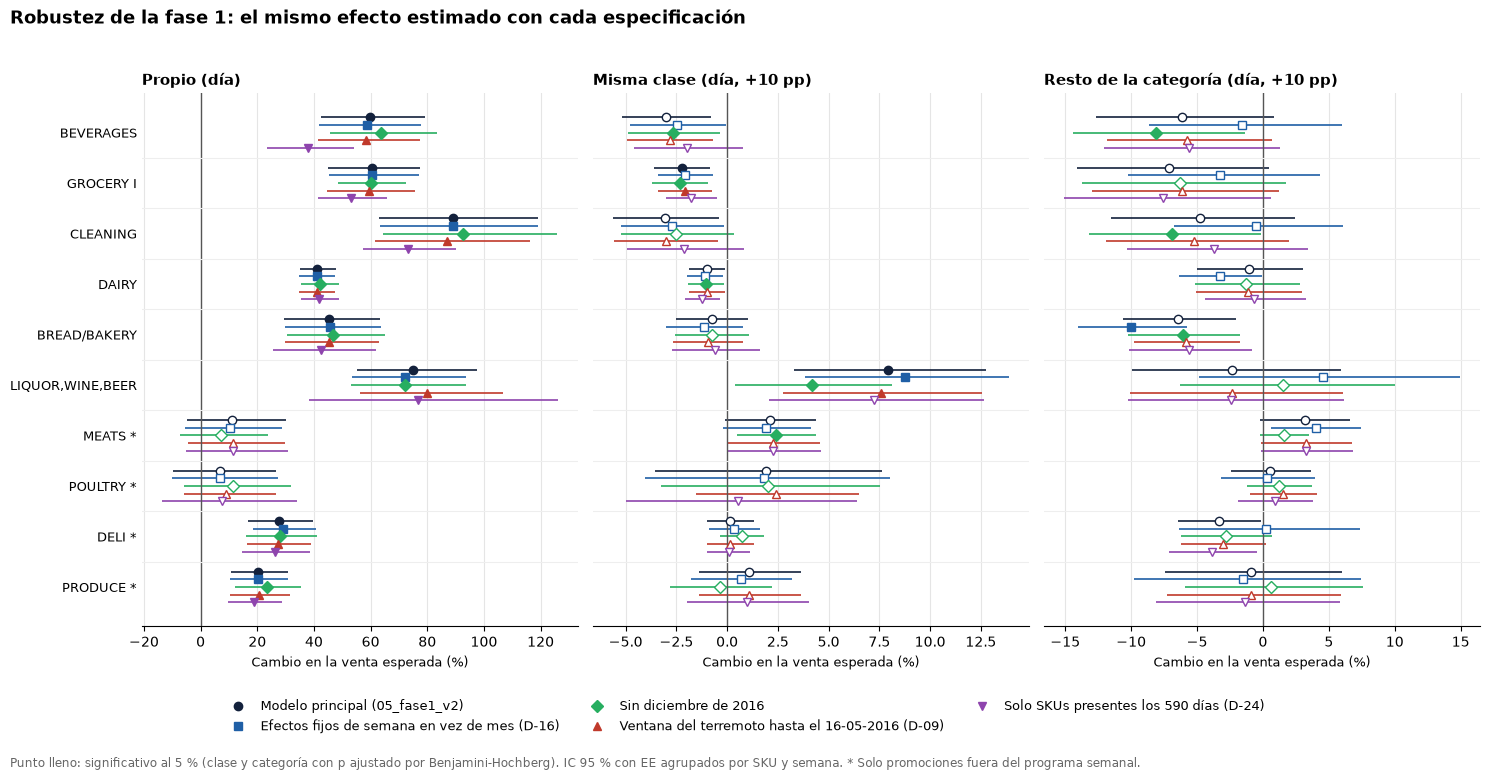

In [13]:
pruebas_figura = [e for e in especificaciones if e != "placebo_adelanto"]
colores = dict(zip(pruebas_figura, ["#13213c", "#1f5fa6", "#27ae60", "#c0392b", "#8e44ad"]))
marcadores = dict(zip(pruebas_figura, ["o", "s", "D", "^", "v"]))
desplazamiento = dict(zip(pruebas_figura, np.linspace(0.3, -0.3, len(pruebas_figura))))
etiquetas = {c: f"{c} *" if c in categorias_programa else c for c in categorias}

fig, ejes = plt.subplots(1, 3, figsize=(15, 7.5), sharey=True)
posiciones = dict(zip(categorias, np.arange(len(categorias))[::-1]))
for eje, (coeficiente, titulo) in zip(ejes, variables_comparadas.items()):
    d = efectos.loc[efectos["coeficiente"] == coeficiente]
    for especificacion in pruebas_figura:
        de = d.loc[d["especificacion"] == especificacion]
        for fila in de.itertuples():
            y = posiciones[fila.categoria] + desplazamiento[especificacion]
            color = colores[especificacion]
            eje.hlines(y, fila.efecto_ic_inf, fila.efecto_ic_sup, color=color, linewidth=1.2)
            eje.plot(fila.efecto, y, marcadores[especificacion], color=color, markersize=6,
                     markerfacecolor=color if fila.p_decision < alfa else "white", zorder=3)
    eje.axvline(0, color="#555555", linewidth=1)
    eje.set_title(titulo, loc="left", fontsize=11, fontweight="bold")
    eje.set_xlabel("Cambio en la venta esperada (%)", fontsize=9)
    eje.grid(axis="x", color="#e5e5e5")
    eje.set_axisbelow(True)
    eje.spines[["top", "right", "left"]].set_visible(False)
    eje.tick_params(axis="y", length=0)
ejes[0].set_yticks(list(posiciones.values()), [etiquetas[c] for c in posiciones], fontsize=9.5)
for y in np.arange(len(categorias) - 1) + 0.5:
    for eje in ejes:
        eje.axhline(y, color="#eeeeee", linewidth=0.8)

leyenda = [plt.Line2D([], [], marker=marcadores[e], color=colores[e], linestyle="", label=especificaciones[e])
           for e in pruebas_figura]
fig.legend(handles=leyenda, loc="lower center", ncol=3, fontsize=9, frameon=False, bbox_to_anchor=(0.5, 0.0))
fig.suptitle("Robustez de la fase 1: el mismo efecto estimado con cada especificación", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.text(0.01, -0.03, "Punto lleno: significativo al 5 % (clase y categoría con p ajustado por Benjamini-Hochberg). "
         "IC 95 % con EE agrupados por SKU y semana. * Solo promociones fuera del programa semanal.",
         fontsize=8.5, color="#666666")
fig.tight_layout(rect=(0, 0.08, 1, 0.96))
fig.savefig(os.path.join(ruta_figuras, f"{prefijo}_efectos.png"), dpi=300, bbox_inches="tight")
plt.show()

**Cómo leer la figura.** Cada categoría tiene cinco puntos, uno por prueba (ver leyenda). Si los cinco están cerca y sus intervalos se traslapan, el resultado de esa categoría es robusto. Un punto que se aleja de los demás indica qué decisión mueve el resultado.

## Paso 11. Exportación

In [14]:
coeficientes.to_csv(os.path.join(ruta_tablas, f"{prefijo}_coeficientes.csv"), index=False)
efectos_netos.to_csv(os.path.join(ruta_tablas, f"{prefijo}_efecto_neto.csv"), index=False)
consistencia.to_csv(os.path.join(ruta_tablas, f"{prefijo}_consistencia.csv"), index=False)
resumen.to_csv(os.path.join(ruta_tablas, f"{prefijo}_resumen.csv"), index=False)
placebo.to_csv(os.path.join(ruta_tablas, f"{prefijo}_placebo.csv"), index=False)
bh.to_csv(os.path.join(ruta_tablas, f"{prefijo}_bh10.csv"), index=False)
muestras.to_csv(os.path.join(ruta_tablas, f"{prefijo}_muestras.csv"), index=False)
for nombre in ["coeficientes", "efecto_neto", "consistencia", "resumen", "placebo", "bh10", "muestras"]:
    print(f"Guardado: {os.path.join(ruta_tablas, f'{prefijo}_{nombre}.csv')}")
print(f"Guardado: {os.path.join(ruta_figuras, f'{prefijo}_efectos.png')}")

Guardado: resultados\tablas\robustez_fase1_coeficientes.csv
Guardado: resultados\tablas\robustez_fase1_efecto_neto.csv
Guardado: resultados\tablas\robustez_fase1_consistencia.csv
Guardado: resultados\tablas\robustez_fase1_resumen.csv
Guardado: resultados\tablas\robustez_fase1_placebo.csv
Guardado: resultados\tablas\robustez_fase1_bh10.csv
Guardado: resultados\tablas\robustez_fase1_muestras.csv
Guardado: resultados\figuras\robustez_fase1_efectos.png


## Paso 12. Lectura automática para la tesis

Frases generadas desde las tablas: **ninguna cifra está escrita a mano** (INSTRUCCIONES §13).

In [15]:
r = resumen.loc[resumen["especificacion"] != "placebo_adelanto"]
print("RESUMEN DE ROBUSTEZ DE LA FASE 1\n")
for variable in nombres_variables.values():
    rv = r.loc[r["variable"] == variable]
    if rv.empty:
        continue
    print(f"{variable}:")
    for fila in rv.itertuples():
        print(f"  - {especificaciones[fila.especificacion]}: misma conclusión en {fila.pct_misma_conclusion:.0f} % de las "
              f"{fila.categorias} categorías; signo igual en {fila.pct_mismo_signo:.0f} %; cambio típico "
              f"{fila.mediana_abs_diferencia_pp:.1f} pp.")

# Categorías y efectos que cambian de conclusión en alguna prueba
if len(cambios):
    print("\nEfectos que cambian de conclusión en al menos una prueba (deben comentarse):")
    for (categoria, variable), g in cambios.groupby(["categoria", "variable"]):
        pruebas = ", ".join(especificaciones[e] for e in g["especificacion"])
        print(f"  - {categoria} · {variable}: cambia en {pruebas}.")
else:
    print("\nNingún efecto cambia de conclusión en las pruebas.")

# Placebo
superan = placebo.loc[~placebo["significativo_bh"], "categoria"].tolist()
no_superan = placebo.loc[placebo["significativo_bh"]]
print(f"\nPlacebo con adelantos: {len(superan)} de {len(placebo)} categorías no muestran efecto de la promoción futura.")
for fila in no_superan.itertuples():
    print(f"  - {fila.categoria}: {fila.efecto_pct:+.1f} % (p corregido = {fila.p_bh:.3f}) -> {fila.lectura}; "
          f"el efecto propio del día pasa de {fila.propio_dia_principal_pct:+.1f} % a {fila.propio_dia_con_adelanto_pct:+.1f} %.")

# Corrección al 10 %
print(f"\nBenjamini-Hochberg al 10 %: efectos de clase y categoría significativos pasan de "
      f"{int(bh['significativo_5'].sum())} a {int(bh['significativo_10'].sum())} de {len(bh)}.")

# Modelos no estimados
no_estimados = muestras.loc[~muestras["estimado"]]
if len(no_estimados):
    print("\nModelos que no se pudieron estimar:")
    for fila in no_estimados.itertuples():
        print(f"  - {fila.especificacion} · {fila.categoria}: {fila.motivo}")
print("\n>>>> Proceso finalizado <<<<")

RESUMEN DE ROBUSTEZ DE LA FASE 1

Propio (día):
  - Efectos fijos de semana en vez de mes (D-16): misma conclusión en 100 % de las 10 categorías; signo igual en 100 %; cambio típico 0.3 pp.
  - Sin diciembre de 2016: misma conclusión en 100 % de las 10 categorías; signo igual en 100 %; cambio típico 3.0 pp.
  - Ventana del terremoto hasta el 16-05-2016 (D-09): misma conclusión en 100 % de las 10 categorías; signo igual en 100 %; cambio típico 0.7 pp.
  - Solo SKUs presentes los 590 días (D-24): misma conclusión en 100 % de las 10 categorías; signo igual en 100 %; cambio típico 1.7 pp.
Misma clase (día, +10 pp):
  - Efectos fijos de semana en vez de mes (D-16): misma conclusión en 90 % de las 10 categorías; signo igual en 100 %; cambio típico 0.3 pp.
  - Sin diciembre de 2016: misma conclusión en 70 % de las 10 categorías; signo igual en 90 %; cambio típico 0.3 pp.
  - Ventana del terremoto hasta el 16-05-2016 (D-09): misma conclusión en 100 % de las 10 categorías; signo igual en 100 %;

## Paso 13. Cómo reportar estos resultados en la tesis

**Dónde va.** Una sección corta "Análisis de robustez" después de los resultados de la fase 1, con la figura `robustez_fase1_efectos.png`, la tabla resumen (`robustez_fase1_resumen.csv`) y la del placebo. El detalle por categoría puede ir en un anexo.

**Estructura sugerida del texto** (completar con las cifras del Paso 12):

1. **Qué se hizo.** "Para evaluar la sensibilidad de los resultados se reestimó el modelo de la fase 1 cambiando, una a la vez, cinco decisiones del análisis previstas en la metodología: [lista de pruebas]. Además, se aplicó una prueba placebo con la promoción de los tres días siguientes."
2. **Resultado general.** "El efecto propio de la promoción mantiene su signo y su significancia en [X] de [Y] combinaciones de categoría y prueba…"
3. **Excepciones.** Nombrar las categorías y pruebas del Paso 12 donde la conclusión cambia, y explicar por qué es plausible (poca información, efecto cerca del límite de significancia, diciembre, etc.).
4. **Placebo.** "La promoción futura no se asocia con las ventas de hoy en [N] de 10 categorías…"; si hay excepciones, interpretarlas con la lectura del Paso 8.
5. **Conclusión.** Qué resultados se consideran robustos y cuáles deben leerse con cautela.

**Cuidados al escribir:**

- Un cambio de significancia con el efecto dentro del intervalo del principal **no contradice** el resultado: dice que está cerca del límite.
- En MEATS, POULTRY, DELI y PRODUCE se habla siempre de promociones **fuera del programa**.
- Robustez no es causalidad: que un efecto sea estable entre especificaciones no elimina el sesgo por la planificación de las promociones (para eso sirve, en parte, el placebo).
- Actualizar en `metodologia.tex` la limitación "Sin análisis de robustez": ahora se hicieron estas pruebas; quedan como trabajo futuro solo las cotas de imputación (D‑25) y otra tienda.

*Escriban aquí su interpretación.*